<a href="https://colab.research.google.com/github/Ahmadfataoni7/UTS-Penambangan-Data/blob/main/UTS_SPK_Status_Darurat_Banjir_Naive_Bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TUGAS UTS MATA KULIAH PENAMBANGAN DATA
“SPK Penentuan Tingkat Status Darurat Kejadian Bencana Banjir
(Siaga Darurat, Tanggap Darurat, Transisi Darurat ke Pemulihan)
dengan Naive Bayes”
NAMA	:	AHMAD FATONI ALI NURDIN
NIM	:	F12.2025.00226
KODE KELAS	:	F12.D302RPL

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (accuracy_score, classification_report, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

LABELS = ["Siaga Darurat", "Tanggap Darurat", "Transisi Darurat ke Pemulihan"]
SHORT = ["Siaga", "Tanggap", "Transisi"]
FITUR = ["Curah_Hujan", "TMA", "Tinggi_Genangan", "KK_Terdampak", "Pengungsi"]
CSV = "Data_Simulasi_Banjir_Kediri.csv"

## 1. Data Collecting


In [2]:
def bangkitkan_data(seed=2026, n_baris=389):
    """Membangkitkan data simulasi catatan harian Pusdalops selama periode status darurat banjir."""
    rng = np.random.default_rng(seed)
    prof = {  # (rata-rata, simpangan baku) per fase
        0: dict(h=(35, 18), tma=(480, 60), g=(8, 8), kk=(25, 20), p=(15, 15)),
        1: dict(h=(70, 30), tma=(640, 70), g=(55, 28), kk=(260, 120), p=(200, 110)),
        2: dict(h=(22, 16), tma=(520, 65), g=(30, 20), kk=(150, 80), p=(90, 60)),
    }
    def draw(ph, level):
        p = prof[ph]
        h = max(0, rng.normal(*p["h"]) * level)
        tma = max(150, rng.normal(*p["tma"]) + 25 * (level - 1))
        g = max(0, rng.normal(*p["g"]) * level)
        kk = max(0, rng.normal(*p["kk"]) * level)
        pg = max(0, rng.normal(*p["p"]) * level * 0.9 + 0.12 * kk)
        return h, tma, g, kk, pg

    rows, date = [], pd.Timestamp("2025-08-15")
    while len(rows) < n_baris:
        eskalasi = rng.random() < 0.55
        level = rng.uniform(0.75, 1.35)
        rencana = [(0, rng.integers(5, 14))]
        if eskalasi:
            rencana += [(1, rng.integers(4, 11)), (2, rng.integers(3, 8))]
        for ph, n in rencana:
            for _ in range(n):
                if len(rows) >= n_baris:
                    break
                h, tma, g, kk, pg = draw(ph, level)
                rows.append([date, round(h, 1), round(tma, 1), round(g, 1),
                             int(round(kk)), int(round(pg)), ph])
                date += pd.Timedelta(days=1)
        date += pd.Timedelta(days=int(rng.integers(1, 4)))
    d = pd.DataFrame(rows, columns=["Date"] + FITUR + ["ph"])
    d["Status_Saat_Ini"] = d["ph"].map(dict(enumerate(LABELS)))
    return d.drop(columns="ph")

if not os.path.exists(CSV):
    try:
        from google.colab import files
        print("Unggah berkas", CSV, "(atau CSV data riil). Batalkan untuk memakai data simulasi bawaan.")
        files.upload()
    except Exception:
        pass

if os.path.exists(CSV):
    df = pd.read_csv(CSV, parse_dates=["Date"])
    print("Data dibaca dari", CSV)
else:
    df = bangkitkan_data()
    df.to_csv(CSV, index=False)
    print("Data simulasi dibangkitkan dan disimpan ke", CSV)

df.head()

Data dibaca dari Data_Simulasi_Banjir_Kediri.csv


,Date,Curah_Hujan,TMA,Tinggi_Genangan,KK_Terdampak,Pengungsi,Status_Saat_Ini
0,2025-08-15,52.7,465.8,6.2,35,15,Siaga Darurat
1,2025-08-16,35.1,526.6,13.7,27,17,Siaga Darurat
2,2025-08-17,43.0,446.5,5.4,41,18,Siaga Darurat
3,2025-08-18,11.6,454.7,15.0,23,16,Siaga Darurat
4,2025-08-19,52.8,592.8,2.6,59,4,Siaga Darurat


## 2. Data Understanding

In [3]:
print("Ukuran data:", df.shape)
print("Rentang tanggal:", df["Date"].min().date(), "sampai", df["Date"].max().date())
print("\nTipe data:\n", df.dtypes)
print("\nNilai kosong:\n", df.isna().sum())
print("\nBaris duplikat:", df.duplicated().sum(), "| Tanggal duplikat:", df["Date"].duplicated().sum())
df[FITUR].describe().T[["mean", "std", "min", "max"]].round(2)

Ukuran data: (389, 7)
Rentang tanggal: 2025-08-15 sampai 2026-10-25

Tipe data:
 Date               datetime64[ns]
Curah_Hujan               float64
TMA                       float64
Tinggi_Genangan           float64
KK_Terdampak                int64
Pengungsi                   int64
Status_Saat_Ini            object
dtype: object

Nilai kosong:
 Date               0
Curah_Hujan        0
TMA                0
Tinggi_Genangan    0
KK_Terdampak       0
Pengungsi          0
Status_Saat_Ini    0
dtype: int64

Baris duplikat: 0 | Tanggal duplikat: 0


,mean,std,min,max
Curah_Hujan,44.93,30.40,0.0,186.6
TMA,530.80,90.78,359.5,868.7
Tinggi_Genangan,26.00,28.85,0.0,131.7
KK_Terdampak,119.42,136.07,0.0,762.0
Pengungsi,84.78,101.67,0.0,513.0


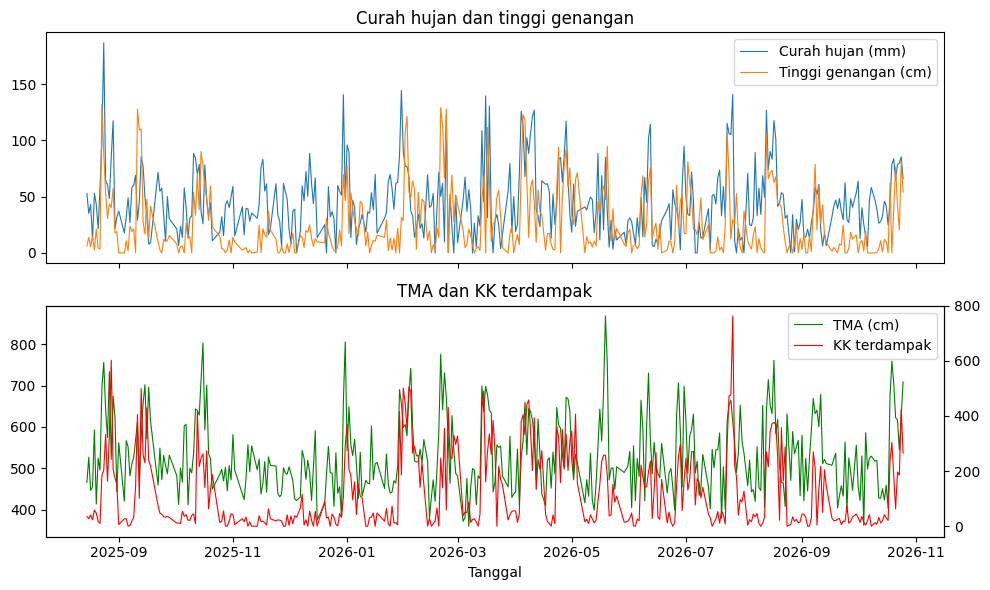

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(df["Date"], df["Curah_Hujan"], lw=.8, label="Curah hujan (mm)")
ax[0].plot(df["Date"], df["Tinggi_Genangan"], lw=.8, label="Tinggi genangan (cm)")
ax[0].set_title("Curah hujan dan tinggi genangan"); ax[0].legend(loc="upper right")
ax[1].plot(df["Date"], df["TMA"], lw=.8, color="green", label="TMA (cm)")
a2 = ax[1].twinx(); a2.plot(df["Date"], df["KK_Terdampak"], lw=.8, color="red", label="KK terdampak")
ax[1].set_title("TMA dan KK terdampak"); ax[1].set_xlabel("Tanggal")
h1, l1 = ax[1].get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels()
ax[1].legend(h1 + h2, l1 + l2, loc="upper right")
plt.tight_layout(); plt.show()

                               Jumlah  Persen
Status_Saat_Ini                              
Siaga Darurat                     212    54.5
Tanggap Darurat                   105    27.0
Transisi Darurat ke Pemulihan      72    18.5


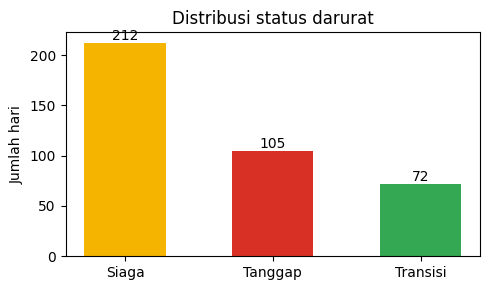


Korelasi antarfitur:


,Curah_Hujan,TMA,Tinggi_Genangan,KK_Terdampak,Pengungsi
Curah_Hujan,1.00,0.40,0.38,0.37,0.40
TMA,0.40,1.00,0.54,0.56,0.63
Tinggi_Genangan,0.38,0.54,1.00,0.63,0.67
KK_Terdampak,0.37,0.56,0.63,1.00,0.72
Pengungsi,0.40,0.63,0.67,0.72,1.00


In [5]:
dist = df["Status_Saat_Ini"].value_counts().reindex(LABELS)
print(pd.DataFrame({"Jumlah": dist, "Persen": (dist / len(df) * 100).round(1)}))

plt.figure(figsize=(5, 3))
plt.bar(SHORT, dist.values, color=["#f4b400", "#d93025", "#34a853"], width=.55)
for i, v in enumerate(dist.values): plt.text(i, v + 3, str(v), ha="center")
plt.ylabel("Jumlah hari"); plt.title("Distribusi status darurat"); plt.tight_layout(); plt.show()

print("\nKorelasi antarfitur:")
df[FITUR].corr().round(2)

## 3. Data Preparation


In [6]:
df = df.sort_values("Date").dropna(subset=FITUR + ["Status_Saat_Ini"]).reset_index(drop=True)
df["Target_Status"] = df["Status_Saat_Ini"].shift(-1)
pasangan = df.dropna(subset=["Target_Status"]).reset_index(drop=True)
print("Jumlah pasangan fitur-target:", len(pasangan))
pasangan[["Date"] + FITUR + ["Status_Saat_Ini", "Target_Status"]].head()

Jumlah pasangan fitur-target: 388


,Date,Curah_Hujan,TMA,Tinggi_Genangan,KK_Terdampak,Pengungsi,Status_Saat_Ini,Target_Status
0,2025-08-15,52.7,465.8,6.2,35,15,Siaga Darurat,Siaga Darurat
1,2025-08-16,35.1,526.6,13.7,27,17,Siaga Darurat,Siaga Darurat
2,2025-08-17,43.0,446.5,5.4,41,18,Siaga Darurat,Siaga Darurat
3,2025-08-18,11.6,454.7,15.0,23,16,Siaga Darurat,Siaga Darurat
4,2025-08-19,52.8,592.8,2.6,59,4,Siaga Darurat,Siaga Darurat


## 4. Modeling


In [7]:
n = len(pasangan)
n_latih = int(round(n * 0.75))
latih, uji = pasangan.iloc[:n_latih], pasangan.iloc[n_latih:]
print(f"Latih: {len(latih)} ({latih['Date'].min().date()} - {latih['Date'].max().date()})")
print(f"Uji  : {len(uji)} ({uji['Date'].min().date()} - {uji['Date'].max().date()})")
print("\nDistribusi target latih:\n", latih["Target_Status"].value_counts().reindex(LABELS).fillna(0).astype(int))
print("\nDistribusi target uji:\n", uji["Target_Status"].value_counts().reindex(LABELS).fillna(0).astype(int))

scaler = StandardScaler().fit(latih[FITUR])
X_latih, X_uji = scaler.transform(latih[FITUR]), scaler.transform(uji[FITUR])
y_latih, y_uji = latih["Target_Status"], uji["Target_Status"]

model = GaussianNB().fit(X_latih, y_latih)
pred = model.predict(X_uji)

Latih: 291 (2025-08-15 - 2026-07-13)
Uji  : 97 (2026-07-14 - 2026-10-24)

Distribusi target latih:
 Target_Status
Siaga Darurat                    152
Tanggap Darurat                   81
Transisi Darurat ke Pemulihan     58
Name: count, dtype: int64

Distribusi target uji:
 Target_Status
Siaga Darurat                    59
Tanggap Darurat                  24
Transisi Darurat ke Pemulihan    14
Name: count, dtype: int64


## 5. Evaluation

In [8]:
akurasi = accuracy_score(y_uji, pred)
print(f"Akurasi data uji  : {akurasi:.2%} ({(pred == y_uji.values).sum()} dari {len(y_uji)})")
print(f"Akurasi data latih: {accuracy_score(y_latih, model.predict(X_latih)):.2%}")

mayoritas = y_uji.value_counts().idxmax()
base = (y_uji == mayoritas).mean()
print(f"Tolok ukur kelas mayoritas ('{mayoritas}'): {base:.2%}")
print(f"Selisih akurasi model - tolok ukur: {(akurasi - base) * 100:+.2f} poin persentase\n")

print(classification_report(y_uji, pred, labels=LABELS, zero_division=0))

Akurasi data uji  : 86.60% (84 dari 97)
Akurasi data latih: 79.73%
Tolok ukur kelas mayoritas ('Siaga Darurat'): 60.82%
Selisih akurasi model - tolok ukur: +25.77 poin persentase

                               precision    recall  f1-score   support

                Siaga Darurat       0.89      0.97      0.93        59
              Tanggap Darurat       0.94      0.71      0.81        24
Transisi Darurat ke Pemulihan       0.67      0.71      0.69        14

                     accuracy                           0.87        97
                    macro avg       0.83      0.80      0.81        97
                 weighted avg       0.87      0.87      0.86        97



                 Prediksi Siaga  Prediksi Tanggap  Prediksi Transisi
Aktual Siaga                 57                 0                  2
Aktual Tanggap                4                17                  3
Aktual Transisi               3                 1                 10

Jumlah prediksi per kelas: {'Siaga': np.int64(64), 'Tanggap': np.int64(18), 'Transisi': np.int64(15)}


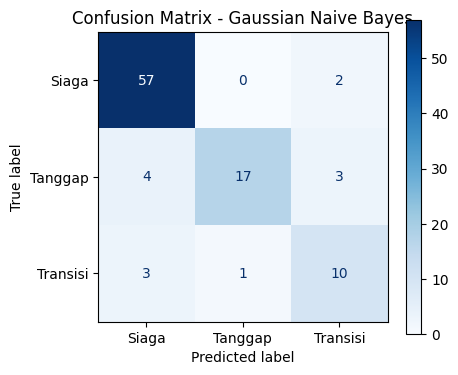

In [9]:
cm = confusion_matrix(y_uji, pred, labels=LABELS)
print(pd.DataFrame(cm, index=["Aktual " + s for s in SHORT], columns=["Prediksi " + s for s in SHORT]))
print("\nJumlah prediksi per kelas:", dict(zip(SHORT, [(pred == l).sum() for l in LABELS])))

fig, ax = plt.subplots(figsize=(4.8, 4))
ConfusionMatrixDisplay(cm, display_labels=SHORT).plot(ax=ax, cmap="Blues")
ax.set_title("Confusion Matrix - Gaussian Naive Bayes"); plt.tight_layout(); plt.show()

## 6. Pemeriksaan Overfitting (tambahan)


In [10]:
X_all, y_all = pasangan[FITUR].values, pasangan["Target_Status"].values
hasil = []
for k, (i_tr, i_te) in enumerate(TimeSeriesSplit(n_splits=5).split(X_all), start=1):
    sc = StandardScaler().fit(X_all[i_tr])
    m = GaussianNB().fit(sc.transform(X_all[i_tr]), y_all[i_tr])
    p = m.predict(sc.transform(X_all[i_te]))
    hasil.append({"Lipatan": k, "Latih": len(i_tr), "Uji": len(i_te),
                  "Akurasi": accuracy_score(y_all[i_te], p),
                  "Macro-F1": f1_score(y_all[i_te], p, labels=LABELS, average="macro", zero_division=0)})
hasil = pd.DataFrame(hasil)
print(hasil.round(3).to_string(index=False))
print(f"\nRata-rata akurasi: {hasil['Akurasi'].mean():.2%} | rata-rata macro-F1: {hasil['Macro-F1'].mean():.2%}")

 Lipatan  Latih  Uji  Akurasi  Macro-F1
       1     68   64    0.938     0.830
       2    132   64    0.844     0.835
       3    196   64    0.703     0.657
       4    260   64    0.656     0.634
       5    324   64    0.859     0.787

Rata-rata akurasi: 80.00% | rata-rata macro-F1: 74.84%
